Today's topics:

Modeling a dataset from start to finish:
* selecting rows with masks
* fitting a plane with `minimize`
* scoring a fit and checking its residuals
* reading a contour plot to make predictions

# How water changes the strength of concrete

Concrete is cement, water, sand, and gravel mixed and left to harden.
The cement reacts with the water (**hydration**), and the reaction products bind the sand and gravel together.

The products fill part of the space the water occupied.
At a higher water/cement ratio more of that space can remain as pores, and a porous paste is generally weaker.


<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/2/29/Concrete_Compression_Testing.jpg/960px-Concrete_Compression_Testing.jpg" alt="A gray concrete cylinder standing between the steel platens of a testing machine, with two strain gauges clipped to its sides" width=300/>

*Photo by Xb-70, public domain, [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Concrete_Compression_Testing.jpg).*

Above: a concrete cylinder in a [compression test](https://en.wikipedia.org/wiki/Compressive_strength).

The press loads the cylinder until it crushes, and the **compressive strength** is the stress at failure.
A common reference age for the test is 28 days.

Engineers describe the water in a mix with the **water/cement ratio**, the mass of water divided by the mass of cement.

For otherwise comparable mixes, [Abrams](https://commons.wikimedia.org/wiki/File:Design_of_concrete_mixtures_(IA_designofconcrete00abrarich).pdf) reported in 1918 that compressive strength decreases as this ratio rises.

Today we'll model the amounts of cement and water directly.

The data are from I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," *Cement and Concrete Research* 28 (1998) 1797-1808, available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength).

Each row is one mix, with the amount of each ingredient in kg per m$^3$ of concrete, the age in days, and the measured strength in MPa.

Suppose a truck delivers a batch with 20 kg/m$^3$ more water than the recipe calls for.
How much strength does the concrete lose, and how far can we trust that number?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

In [2]:
#@title Load the concrete table and give the columns short names (click ▶ to run) { display-mode: "form" }
data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/concrete.csv')
data.columns = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
                'coarse_agg', 'fine_agg', 'age', 'strength']

# Reading and selecting a table

## Read and inspect

In [3]:
display(data)

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.284354
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.178794
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.696601
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.768036


One row is one mix.
The ingredient columns are in kg/m$^3$, `age` is in days, and `strength` is in MPa.

## Select one population

Slag and fly ash replace part of the cement, so we keep the plain-cement mixes: the ones with none of either.
Strength also changes as the concrete keeps hardening, so we keep one age, 28 days.

Each condition is a mask, and `&` keeps the rows where both masks are `True`.

In [4]:
is_plain = (data['slag'] == 0) & (data['fly_ash'] == 0)
is_28 = data['age'] == 28

mixes = data.loc[is_plain & is_28]
print(np.sum(is_plain), np.sum(is_28), len(mixes))  # plain mixes, 28-day mixes, both

232 425 80


Our population is the 80 rows in `mixes`.

Let's pull out cement, water, and strength and check their ranges.

In [5]:
cement = mixes['cement']
water = mixes['water']
strength = mixes['strength']

print(f'cement:   {np.min(cement):.0f} to {np.max(cement):.0f} kg/m3')
print(f'water:    {np.min(water):.0f} to {np.max(water):.0f} kg/m3')
print(f'strength: {np.min(strength):.0f} to {np.max(strength):.0f} MPa')

cement:   200 to 540 kg/m3
water:    140 to 228 kg/m3
strength: 12 to 80 MPa


# Plotting strength against the mix

## Water/cement ratio

The ratio is one elementwise division of two columns.

Text(0, 0.5, '28-day strength (MPa)')

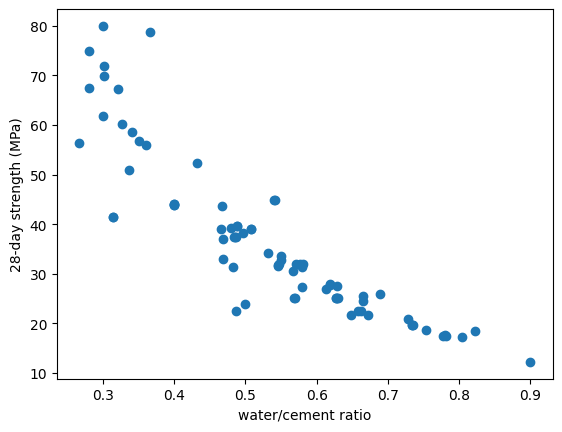

In [6]:
wc = water / cement

fig, ax = plt.subplots()
ax.scatter(wc, strength)
ax.set_xlabel('water/cement ratio')
ax.set_ylabel('28-day strength (MPa)')

The mixes with more water per unit of cement are weaker, the same trend Abrams reported.

We'll leave the ratio out of our model.
We'll use the cement and water amounts as two separate inputs.

## Color for a third variable

Cement and water give the two axes, and the color shows the strength.
We use the `Greys` colormap, and the black outlines keep the light markers visible in greyscale.

Text(0, 0.5, 'water (kg/m3)')

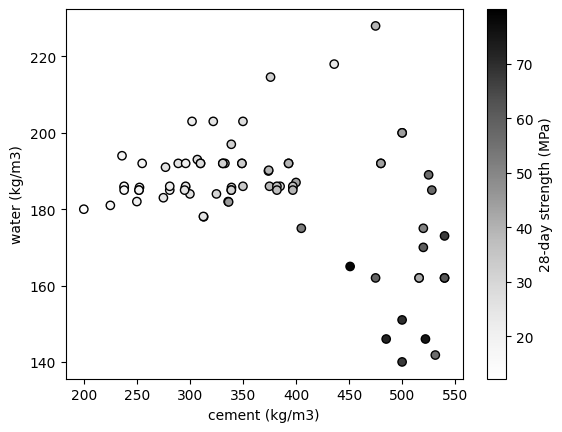

In [7]:
fig, ax = plt.subplots()
im = ax.scatter(cement, water, c=strength, cmap='Greys', edgecolor='k')
cb = fig.colorbar(im, ax=ax)
cb.set_label('28-day strength (MPa)')
ax.set_xlabel('cement (kg/m3)')
ax.set_ylabel('water (kg/m3)')

The dark marks, the strong mixes, sit toward the lower right: more cement and less water.
A plane in these two inputs is the simplest model for that trend.

# Scoring a fit

We'll score every model with the same two helpers: `rmse` and `r_squared`.

In [8]:
def rmse(y, y_fit):
    """Root-mean-square error, in the units of y."""
    return np.sqrt(np.mean((y - y_fit)**2))

def r_squared(y, y_fit):
    """R2 of a fit: 1 minus the squared misfit over the squared spread of y."""
    return 1 - np.sum((y - y_fit)**2) / np.sum((y - np.mean(y))**2)

A model that always guesses the mean strength sets the baseline.

In [9]:
print(f'RMSE of the mean-only guess = {rmse(strength, np.mean(strength)):.1f} MPa')

RMSE of the mean-only guess = 15.8 MPa


The water/cement ratio gives a second baseline, a line fitted with `stats.linregress`.

In [10]:
fit_wc = stats.linregress(wc, strength)
strength_wc = fit_wc.slope * wc + fit_wc.intercept
print(f'RMSE = {rmse(strength, strength_wc):.1f} MPa')
print(f'R2 = {r_squared(strength, strength_wc):.3f}')

RMSE = 7.3 MPa
R2 = 0.788


# Fitting a plane with `minimize`

A plane in two inputs has three parameters:

$$\text{strength} = a + b\,(\text{cement}) + c\,(\text{water})$$

With one input this is the line $y = a + b x$ again, and we've added one term.

We write it as a model function with the inputs first and the parameters after them.

In [11]:
def plane(x, y, a, b, c):
    """Strength in MPa from a + b * x + c * y.

    x:  cement in kg/m3
    y:  water in kg/m3
    a:  height of the plane at x = 0, y = 0, in MPa
    b:  MPa per kg/m3 of cement
    c:  MPa per kg/m3 of water
    """
    return a + b * x + c * y

The objective follows the least-squares recipe: it unpacks the parameters, predicts the strengths, subtracts them from the data, squares, and averages.

In [12]:
def mse_plane(params):
    a, b, c = params
    residuals = strength - plane(cement, water, a, b, c)
    return np.mean(residuals**2)

`x0` has one starting value for each of the three parameters, in the order of the unpack line.
We start all three at zero.

In [13]:
res = optimize.minimize(mse_plane, [0, 0, 0])
a_fit, b_fit, c_fit = res.x
print(res.success)
print(f'a = {a_fit:.1f} MPa')
print(f'b = {b_fit:.3f} MPa per kg/m3 of cement')
print(f'c = {c_fit:.3f} MPa per kg/m3 of water')

True
a = 51.8 MPa
b = 0.124 MPa per kg/m3 of cement
c = -0.333 MPa per kg/m3 of water


At fixed water in this fitted plane, more cement goes with higher strength.
At fixed cement, more water goes with lower strength.

Each coefficient is the change in fitted strength for one more kg/m$^3$ of that ingredient, with the other ingredient held fixed.
The intercept `a` is the height of the plane at zero cement and zero water, far outside our mixes.

# Checking the fit

## RMSE and $R^2$

We call `plane` with our fitted parameters and score the result with the same helpers.

In [14]:
strength_fit = plane(cement, water, a_fit, b_fit, c_fit)

print(f'RMSE = {rmse(strength, strength_fit):.1f} MPa')
print(f'R2 = {r_squared(strength, strength_fit):.3f}')

RMSE = 6.5 MPa
R2 = 0.833


The plane's typical miss is smaller than the miss of the mean-only guess, and smaller than the miss of the water/cement line.

## Residuals

An RMSE is one number for all 80 mixes.
We plot each residual against the fitted strength to see where the misses are.

Text(0, 0.5, 'residual (MPa)')

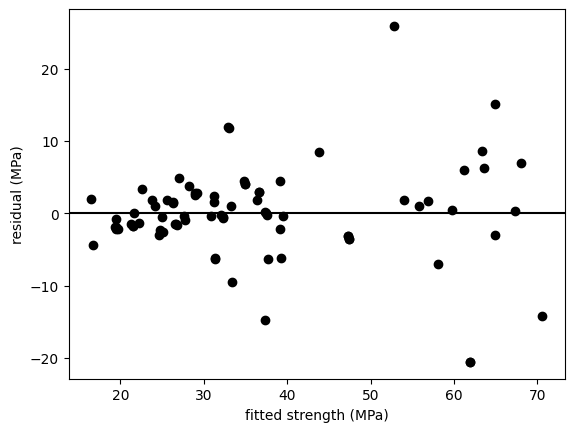

In [15]:
residuals = strength - strength_fit

fig, ax = plt.subplots()
ax.scatter(strength_fit, residuals, color='k')
ax.axhline(0, color='black')
ax.set_xlabel('fitted strength (MPa)')
ax.set_ylabel('residual (MPa)')

The residuals stay close to zero on the left and spread out on the right.
Let's compare the two halves with a mask on the fitted strength.

In [16]:
is_weak = strength_fit < 40
is_strong = strength_fit >= 40

print(f'fitted below 40 MPa:  {np.sum(is_weak)} mixes, residual std = {np.std(residuals.loc[is_weak]):.1f} MPa')
print(f'fitted 40 MPa and up: {np.sum(is_strong)} mixes, residual std = {np.std(residuals.loc[is_strong]):.1f} MPa')

fitted below 40 MPa:  59 mixes, residual std = 4.2 MPa
fitted 40 MPa and up: 21 mixes, residual std = 10.5 MPa


The misses are not spread equally across the fitted range.

The high fitted-strength group has larger errors under the plane, and the cause is open.
Other ingredients, nonlinear behavior, and measurement variation are all possibilities.

For a strong mix, the overall RMSE understates the spread we see on the right of the plot.

# Reading a contour plot

The plane gives a fitted strength at every point in the (cement, water) plane.
A **contour plot** draws that surface in two dimensions, and each shaded band covers points with about the same fitted strength.

We fill the bands with a greyscale map and put the 80 mixes on top.

Text(0, 0.5, 'water (kg/m3)')

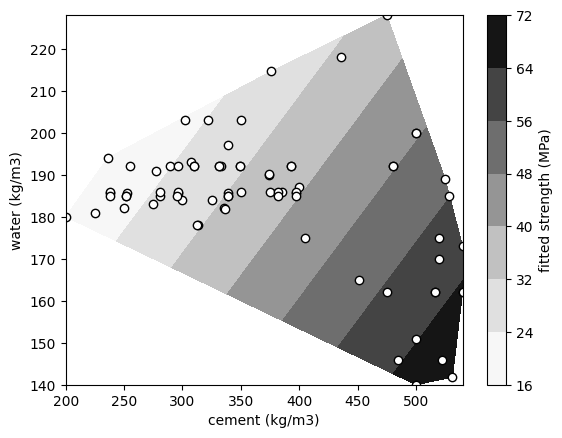

In [17]:
fig, ax = plt.subplots()
cs = ax.tricontourf(cement, water, strength_fit, cmap='Greys')
ax.scatter(cement, water, color='white', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted strength (MPa)')
ax.set_xlabel('cement (kg/m3)')
ax.set_ylabel('water (kg/m3)')

The bands are straight and parallel because the form is a plane.

Moving right, toward more cement, crosses into darker bands.
Moving up, toward more water, crosses into lighter ones.

Moving along one band leaves the fitted strength unchanged, so cement and water trade off.
The ratio of the two coefficients gives the trade:

In [18]:
print(f'{100 * b_fit / -c_fit:.0f} kg/m3 more water offsets 100 kg/m3 more cement')

37 kg/m3 more water offsets 100 kg/m3 more cement


The filled map covers the region spanned by the mixes and stops outside it.
The lower left and the upper right corners hold no mixes, so no data support the plane there.

To predict from the plane, we call `plane` at a mix inside the cloud of white markers.
A mix with 400 kg/m$^3$ of cement and 185 kg/m$^3$ of water sits in the 32 to 40 MPa band.

In [19]:
print(f'{plane(400, 185, a_fit, b_fit, c_fit):.1f} MPa')

39.9 MPa


### [Check your understanding]

Let's use the plane for the truck.

The recipe calls for 180 kg/m$^3$ of water with 350 kg/m$^3$ of cement, and the truck arrives with 200 kg/m$^3$.
Here is the contour with both mixes marked in red.

Text(0, 0.5, 'water (kg/m3)')

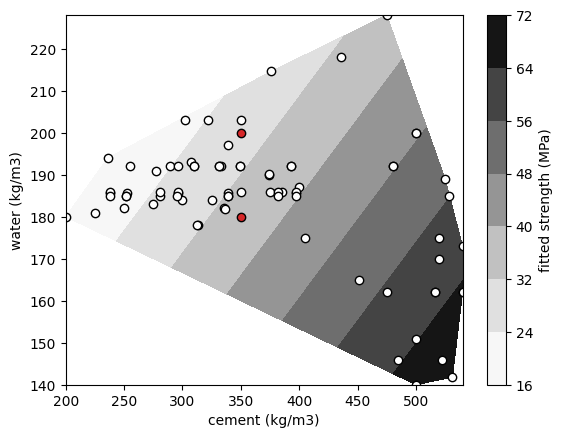

In [20]:
fig, ax = plt.subplots()
cs = ax.tricontourf(cement, water, strength_fit, cmap='Greys')
ax.scatter(cement, water, color='white', edgecolor='k')
ax.scatter([350, 350], [180, 200], color='tab:red', edgecolor='k')
cb = fig.colorbar(cs, ax=ax)
cb.set_label('fitted strength (MPa)')
ax.set_xlabel('cement (kg/m3)')
ax.set_ylabel('water (kg/m3)')

1. Print the fitted strength of each mix with `plane(350, 180, ...)` and `plane(350, 200, ...)`, and print their difference.
2. Compare the difference with the RMSE.
   Do both red markers sit inside the cloud of white markers?

*A mix with 300 kg/m$^3$ of cement and 160 kg/m$^3$ of water is inside both ranges.*

*Would we trust the plane there, and why? Look at the cloud of markers as well as the separate ranges.*

# Summary

On selecting rows:
* Two masks joined with `&` keep the plain-cement mixes at 28 days, and every fit afterward describes only those 80 mixes.

On fitting a plane:
* A plane in two inputs is a line with one more parameter, and its objective has one more entry to unpack.
* `x0` has one start per parameter, and each fitted coefficient is a change in strength per unit of one input, with the other input held fixed.

On checking the fit:
* RMSE gives the typical miss in MPa, $R^2$ compares the fit with the mean-only guess, and a residual plot shows where the misses are.
* A mask on the fitted strength splits the residuals, and the strong mixes have larger residuals.

On contours and predictions:
* Each contour band covers mixes with about the same fitted strength, and a plane gives straight parallel bands.
* A prediction between nearby mixes is an interpolation, and a point can sit inside every input's range and still lie outside the data.

The answer to our question about the truck: the plane puts the cost of 20 kg/m$^3$ of extra water at about 7 MPa for a 28-day plain mix with 350 kg/m$^3$ of cement.

The plane's typical miss is also about 7 MPa, so we'd report the change as a rough model estimate.

## Further reading

* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html)
* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* [`Axes.tricontourf` documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.tricontourf.html)
* The data: Yeh, I-C. "Modeling of strength of high performance concrete using artificial neural networks." *Cement and Concrete Research* 28 (12), 1797-1808 (1998). [DOI 10.1016/S0008-8846(98)00165-3](https://doi.org/10.1016/S0008-8846(98)00165-3). The [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) copy is licensed CC BY 4.0, so we attribute I-Cheng Yeh and the repository record.
* Abrams, D. A. [*Design of Concrete Mixtures*](https://commons.wikimedia.org/wiki/File:Design_of_concrete_mixtures_(IA_designofconcrete00abrarich).pdf), Structural Materials Research Laboratory Bulletin 1, Lewis Institute (1918), for the water/cement ratio
* Photo credit: concrete compression test, Xb-70, public domain, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Concrete_Compression_Testing.jpg)